# Pontin et al. (2023): six-degree-of-freedom cooling by elliptic coherent scattering

A. Pontin, H. Fu, M. Toroš, T. S. Monteiro and P. F. Barker, *Simultaneous cavity cooling of all six
degrees of freedom of a levitated nanoparticle*, Nat. Phys. **19**, 1003–1008 (2023),
[doi:10.1038/s41567-023-02006-6](https://doi.org/10.1038/s41567-023-02006-6) (open version:
arXiv:2205.10193v1, *... by elliptic coherent scattering*; the numbers below are from that version,
whose supplement is not available here).

A prolate silica ellipsoid in a slightly elliptically polarised 1064 nm tweezer scatters light into a
high-finesse cavity. Detuned to the red of the two tightly confined librations, the coherent
scattering cools the centre of mass in the polarisation plane to 126 ± 17 μK and 212 ± 16 μK, the
motion along the beam to 6 ± 2 mK and the two librations to 6.3 ± 1.4 mK and 4.4 ± 0.5 mK at
1.1 × 10⁻⁶ mbar. The third angle, the spin about the long axis, is confined only by the ellipticity
and the small difference of the two short radii; it is freely diffusing at high pressure, which
couples the other two librations (frequencies ω±), and is confined at the lowest pressures.

This notebook

1. computes the six trap frequencies of the paper's ellipsoid and its gas damping
   (`Ellipsoid`, `Tweezer.elliptical_polarisation`, `Trap.Ωθ`, `Trap.Γrot_j`);
2. builds the coherent-scattering `MultiTrap` with all six dimensions and computes the cooled
   occupations against pressure and the heterodyne spectrum;
3. compares linear and nonlinear `CavitySimulation` traces of the translations;
4. checks the spin-induced splitting ω± of the two librations in the time domain
   (`RigidBodySimulation`) against the paper's formula.

**Comparisons stated before running:** spin-libration frequency ≈ 17 kHz for $r_2 - r_1$ = 0.5 nm and
33 kHz for 1.7 nm (paper's analytic values; 32 kHz observed); librations 357 and 377 kHz and
translations 135, 148 and 33 kHz (measured, Figs. 2c and 3); gas damping
γ/2π = P × (533, 751, 758, 646, 702, 694) Hz/mbar for (x, y, z, α, β, γ) (paper, after Cavalleri et
al.); the effective temperatures above; ω± from the paper's formula.

| Quantity | Value used | Source |
|---|---|---|
| particle | ellipsoid, radii 83.7, 84.2 (or 85.4, +1σ) and 109 nm, ρ = 1850 kg/m³, εr = 1.98 | text |
| tweezer | 1064 nm, 235 mW, waists 831 nm (∥ polarisation) and 771 nm, ellipticity ψ = 14.5° | text |
| cavity | L = 12.23 mm, finesse 31 000, κ/2π = 2 × 198 kHz (the paper quotes the half linewidth), waist 60 μm | text |
| detuning | Δ/2π = −362 kHz (red) | text |
| position | 0.155 λ from an antinode, Φ = 2π × 0.155 | text |
| cavity orientation | perpendicular to the major polarisation axis (θ = 90°) | assumption (the supplement gives the angle) |

Axes: the paper's polarisation (major axis) is its $x$ and the cavity its $y$; in levisim the major axis
is $y$ and the cavity axis $x$. The paper's Euler angles map onto levisim's small rotations about the lab
axes as α (in the polarisation plane) → `'γ'` (about the beam axis $z$), β (out of the plane, towards
the beam) → `'α'` (about the cavity axis $x$), and γ (the spin about the long axis) → `'β'` (about the
polarisation $y$). Tables below use the paper's names.

In [1]:
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))  # paper_tools.py sits next to this notebook

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, welch

from levisim.core.constants import kB, ħ, π
from levisim.core.logger import logger
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import degrees, kHz, mbar, mm, mW, nm, μm, μs
from levisim.multiphysics.multitrap import MultiTrap
from levisim.physics import Ellipsoid, Gas, Trap, Tweezer
from levisim.physics.material import Material
from levisim.physics.particle import rotation_matrix_to_quaternion
from levisim.simulation import RigidBodySimulation

from paper_tools import heterodyne, occupations

logger.remove()
set_plt_rcParams_to_xmgrace_style()
t_start = time.time()

SILICA = Material('silica (Pontin et al. 2023)', 1850.0, permittivity=1.98)
# body axes: the long axis c along the polarisation y, the radius b along the cavity axis x, a along z
ORIENTATION = rotation_matrix_to_quaternion(np.array([[0, 1, 0], [0, 0, 1], [1, 0, 0]], dtype=float))
PAPER_NAMES = {'x': 'y (cavity)', 'y': 'x (polarisation)', 'z': 'z (beam)', 'α': 'β', 'β': 'γ (spin)', 'γ': 'α'}


def ellipsoid(b=84.2*nm, Φ=2*π*0.155):
    return Ellipsoid(83.7*nm, b, 109*nm, material=SILICA, λ=1064*nm, orientation=ORIENTATION, Φ=Φ)


def tweezer():
    return Tweezer(λ=1064*nm, Power=235*mW, wx0=771*nm, wy0=831*nm, θ=90*degrees,
                   polarisation=Tweezer.elliptical_polarisation(14.5*degrees))

## 1. Trap frequencies and gas damping

In [2]:
measured = {'x': 148, 'y': 135, 'z': 33, 'α': 377, 'β': 32, 'γ': 357}  # kHz, levisim axes
for b in (84.2*nm, 85.4*nm):
    trap = Trap(tweezer=tweezer(), particle=ellipsoid(b), gas=Gas(P=1*mbar, T=300.0), finite_size_torque=True)
    Ω = {**trap.Ωj, **trap.Ωθ}
    print(f'r2 - r1 = {(b - 83.7*nm) / nm:.1f} nm:')
    for axis in ('x', 'y', 'z', 'γ', 'α', 'β'):
        print(f'  {PAPER_NAMES[axis]:18s} Ω/2π = {Ω[axis] / kHz:6.1f} kHz   (measured {measured[axis]} kHz)')
    point_dipole = Trap(tweezer=tweezer(), particle=ellipsoid(b), finite_size_torque=False)
    print(f'  point-dipole torques alone (finite_size_torque=False): β {point_dipole.Ωθ["α"] / kHz:.1f}, '
          f'γ (spin) {point_dipole.Ωθ["β"] / kHz:.1f}, α {point_dipole.Ωθ["γ"] / kHz:.1f} kHz')

paper_damping = {'y': 533, 'x': 751, 'z': 758, 'γ': 646, 'α': 702, 'β': 694}  # Hz/mbar, levisim axes
Γ_trans = dict(zip('xyz', np.diag(trap.Γth_tensor)))
print('\ngas damping γ/2π at 1 mbar, 300 K (Martinetz et al. 2018, full accommodation):')
for axis in ('y', 'x', 'z', 'γ', 'α', 'β'):
    Γ = Γ_trans[axis] if axis in 'xyz' else trap.Γrot_j[axis]
    print(f'  {PAPER_NAMES[axis]:18s} levisim {Γ / (2 * π):5.0f} Hz   paper {paper_damping[axis]} Hz')

# depth of the spin potential: U(φ) = (K/2) sin²φ for a rotation φ about the long axis
for b in (84.2*nm, 85.4*nm):
    trap_b = Trap(tweezer=tweezer(), particle=ellipsoid(b), finite_size_torque=True)
    K_spin = trap_b.torque_stiffness_tensor[1, 1]
    print(f'spin potential depth for r2 - r1 = {(b - 83.7*nm) / nm:.1f} nm: {K_spin / 2 / kB:.0f} K (paper ≈ 20 K)')
print(f'static spin torque of the elliptical light about z: {trap.static_torque[2]:.2e} N m '
      f'(a tilt of {trap.static_torque[2] / trap.torque_stiffness_tensor[2, 2]:.1e} rad)')

r2 - r1 = 0.5 nm:
  y (cavity)         Ω/2π =  166.5 kHz   (measured 148 kHz)
  x (polarisation)   Ω/2π =  154.5 kHz   (measured 135 kHz)
  z (beam)           Ω/2π =   48.0 kHz   (measured 33 kHz)
  α                  Ω/2π =  369.9 kHz   (measured 357 kHz)
  β                  Ω/2π =  379.7 kHz   (measured 377 kHz)
  γ (spin)           Ω/2π =   12.7 kHz   (measured 32 kHz)
  point-dipole torques alone (finite_size_torque=False): β 387.0, γ (spin) 17.7, α 368.6 kHz
r2 - r1 = 1.7 nm:
  y (cavity)         Ω/2π =  166.4 kHz   (measured 148 kHz)
  x (polarisation)   Ω/2π =  154.4 kHz   (measured 135 kHz)
  z (beam)           Ω/2π =   48.0 kHz   (measured 33 kHz)
  α                  Ω/2π =  357.7 kHz   (measured 357 kHz)
  β                  Ω/2π =  380.0 kHz   (measured 377 kHz)
  γ (spin)           Ω/2π =   23.1 kHz   (measured 32 kHz)
  point-dipole torques alone (finite_size_torque=False): β 387.3, γ (spin) 32.3, α 356.4 kHz

gas damping γ/2π at 1 mbar, 300 K (Martinetz et al. 2018, ful

With the finite-size torque (`finite_size_torque=True`, levisim's default for a non-spherical
particle, set explicitly here) the two tightly confined librations come out at 369.9 and 379.7 kHz
(nominal radii) and 357.7 and 380.0 kHz (+1σ), against the measured 357 and 377 kHz, and the spin
libration at 12.7 and 23.1 kHz. With the point-dipole torques alone (`finite_size_torque=False`, the
paper's analytic model) the spin libration is at 17.7 and 32.3 kHz, as the paper's own analytic 17
and 33 kHz, and the out-of-plane libration at 387 kHz: the finite-size term turns the radius along the
cavity axis towards the softer beam axis, which lowers the spin frequency, so with it a larger
difference of the short radii than the paper's 1.7 nm would give the observed 32 kHz. The translational frequencies are 12–45 % high: levisim's tweezer is paraxial, and at NA 0.77
the true focal field is weaker than the Gaussian with the quoted waists (the paper fitted its geometry
to the measured frequencies with its own model). The damping rates agree to 0–19 %; the largest
difference is along the long axis (633 against 533 Hz/mbar), where the paper's Cavalleri et al. model
and the diffuse-reflection model of Martinetz et al. differ most.

## 2. Coherent scattering: couplings, occupations and spectrum

All six dimensions enter one `MultiTrap`. With the tweezer's minor polarisation axis along the cavity,
the in-plane libration (paper's α) scatters into the cavity through the ellipticity (its coupling
∝ sin ψ, complex, Schäfer et al. 2021), x and z through the standing wave and the Gouy phase.
The paper's β and γ scatter into the cavity mode polarised along the beam, which levisim does not
model, and its x (the major polarisation axis) is not coupled at θ = 90°. The +1σ radius
(85.4 nm) is used, for which the spin libration is confined at 23 kHz (32 kHz, as observed, with the
point-dipole torques alone).

In [3]:
def pontin_multitrap(P, axes=('x', 'y', 'z', 'α', 'β', 'γ')):
    return MultiTrap(tweezers=[tweezer()], beads=[ellipsoid(85.4*nm)], Cartesian_axes_per_trap=axes,
                     gas_kwargs=dict(P=P, T=300.0),
                     cavity_kwargs=dict(L=12.23*mm, w=60*μm, Finesse=31_000, κ=2*198*kHz, Δ=-362*kHz),
                     trap_kwargs=[{'finite_size_torque': True}], photon_recoil=True)


def temperatures(mt):
    n = occupations(mt)
    return {label[0]: ħ * dim.Ω * (n[label] + 0.5) / kB for label, dim in mt.dimensions.items()}


mt = pontin_multitrap(1.1e-6*mbar)
print(f'stable: {mt.is_stable}')
T_low = temperatures(mt)
paper_T = {'x': 212e-6, 'y': 126e-6, 'z': 6e-3, 'γ': 6.3e-3, 'α': 4.4e-3}
for label, dim in mt.dimensions.items():
    axis = label[0]
    paper = f'{paper_T[axis] * 1e3:.3g} mK' if axis in paper_T else '—'
    print(f'{PAPER_NAMES[axis]:18s} Ω/2π = {dim.Ω / kHz:6.1f} kHz, |g|/2π = {abs(dim.g) / kHz:7.3g} kHz, '
          f'T(1.1e-6 mbar) = {T_low[axis] * 1e3:9.3g} mK   (paper {paper})')

stable: True
y (cavity)         Ω/2π =  172.4 kHz, |g|/2π =    52.6 kHz, T(1.1e-6 mbar) =    0.0386 mK   (paper 0.212 mK)
x (polarisation)   Ω/2π =  154.9 kHz, |g|/2π = 3.4e-15 kHz, T(1.1e-6 mbar) =  3.58e+05 mK   (paper 0.126 mK)
z (beam)           Ω/2π =   62.2 kHz, |g|/2π =    54.2 kHz, T(1.1e-6 mbar) =     0.143 mK   (paper 6 mK)
β                  Ω/2π =  382.8 kHz, |g|/2π =       0 kHz, T(1.1e-6 mbar) =   3.1e+05 mK   (paper 4.4 mK)
γ (spin)           Ω/2π =   23.1 kHz, |g|/2π =       0 kHz, T(1.1e-6 mbar) =     3e+05 mK   (paper —)
α                  Ω/2π =  360.3 kHz, |g|/2π =    1.18 kHz, T(1.1e-6 mbar) =      16.5 mK   (paper 6.3 mK)


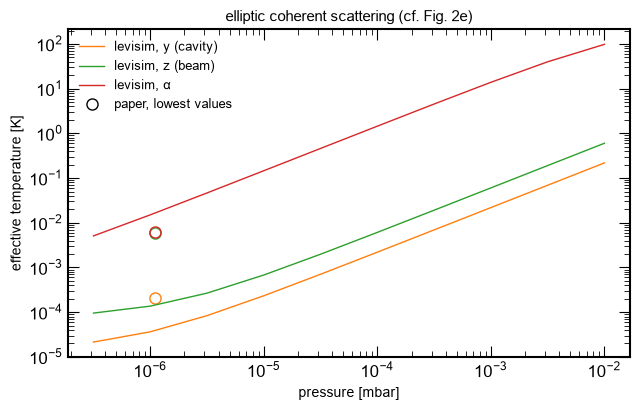

In [4]:
pressures = np.logspace(-6.5, -2, 10) * mbar
T_vs_P = {axis: [] for axis in ('x', 'z', 'γ')}
for P in pressures:
    T = temperatures(pontin_multitrap(P))
    for axis in T_vs_P:
        T_vs_P[axis].append(T[axis])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
colours = {'x': 'C1', 'z': 'C2', 'γ': 'C3'}
for axis, values in T_vs_P.items():
    ax.loglog(pressures / mbar, values, color=colours[axis], label=f'levisim, {PAPER_NAMES[axis]}')
    ax.plot(1.1e-6, paper_T[axis], 'o', color=colours[axis], mfc='none', ms=8)
ax.plot([], [], 'ko', mfc='none', label='paper, lowest values')
ax.set_xlabel('pressure [mbar]')
ax.set_ylabel('effective temperature [K]')
ax.set_title('elliptic coherent scattering (cf. Fig. 2e)', fontsize=11)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

heterodyne peaks [kHz]: [ 48.1 160.1 360.3] ; uncoupled frequencies [kHz]: {'y (cavity)': np.float64(172.4), 'x (polarisation)': np.float64(154.9), 'z (beam)': np.float64(62.2), 'α': 360.3}


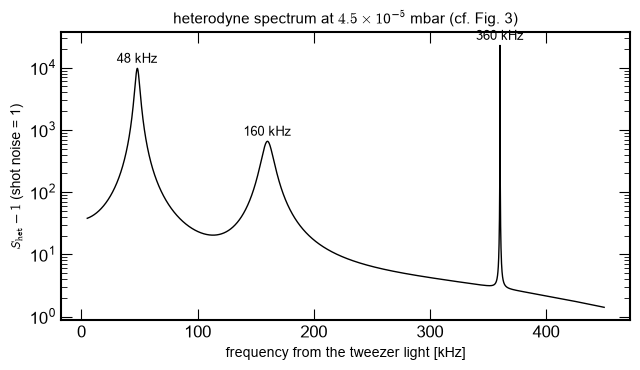

In [5]:
mt_spec = pontin_multitrap(4.5e-5*mbar)
f = np.linspace(5, 450, 4000) * kHz
S = heterodyne(mt_spec, f)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogy(f / kHz, S - 1, 'k', lw=1)
peaks, _ = find_peaks(np.log(S - 1), prominence=1)
for peak in peaks:
    ax.annotate(f'{f[peak] / kHz:.0f} kHz', (f[peak] / kHz, (S - 1)[peak]), textcoords='offset points', xytext=(0, 4),
                ha='center', fontsize=9)
print('heterodyne peaks [kHz]:', np.round(f[peaks] / kHz, 1), '; uncoupled frequencies [kHz]:',
      {PAPER_NAMES[label[0]]: round(dim.Ω / kHz, 1) for label, dim in mt_spec.dimensions.items() if abs(dim.g) > 0})
ax.set_xlabel('frequency from the tweezer light [kHz]')
ax.set_ylabel(r'$S_\mathrm{het} - 1$ (shot noise = 1)')
ax.set_title(r'heterodyne spectrum at $4.5\times10^{-5}$ mbar (cf. Fig. 3)', fontsize=11)
fig.tight_layout()

At the lowest pressure levisim predicts 0.04 mK for the cavity-axis motion (measured 0.21 mK) and
0.14 mK along the beam (measured 6 mK, which the paper attributes to a coupling to the spin it
observes but does not model), and 16.5 mK for the in-plane libration (measured 6.3 mK). In the
heterodyne spectrum the coupled modes are dressed by the cavity to 48, 160 and 360 kHz (z, cavity
axis and in-plane libration), against the 33, 148 and 357 kHz of the paper's Fig. 3. Laser
frequency noise, which the paper identifies in its spectra, is not modelled and heats the
translations; the libration's coupling (1.2 kHz) depends on the exact ellipticity and the position
in the standing wave (∝ cos Φ), both quoted only to about 7 %. The paper's x and β are not cooled in
this model (see above).

## 3. Linear and nonlinear cavity simulations of the translations

`CavitySimulation(model='nonlinear')` integrates the full dipole energy of the translations and the
cavity field; it does not include librations (it raises for a `MultiTrap` with librational
dimensions), so the translations are simulated in a translational `MultiTrap` at 10⁻⁵ mbar. The
occupations from the traces are compared with the linear model's steady state.

nonlinear equilibrium: displacement [-1.8e+01 -1.3e-15  9.2e+01] nm, |α| = 5995 (MultiTrap, at the trap centre: 5168)
y (cavity)   n: MultiTrap   27.7, linear traces   28.1 ±  0.3; nonlinear model linearised at its equilibrium   32.9, nonlinear traces   35.2 ±  1.3
z (beam)     n: MultiTrap  227.1, linear traces  226.6 ±  3.1; nonlinear model linearised at its equilibrium  216.5, nonlinear traces  396.7 ± 138.8
4 runs of 105 ms each, second halves analysed


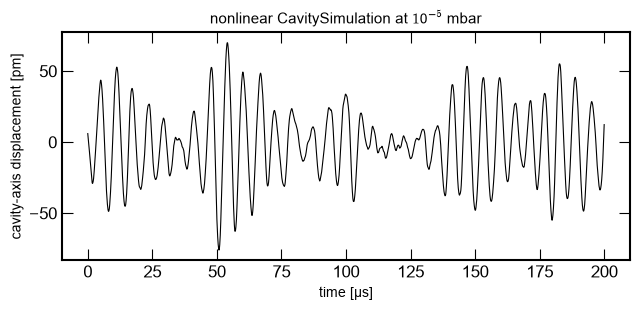

In [6]:
from levisim.simulation.nonlinear_cavity import NonlinearCavityModel

mt3 = pontin_multitrap(1e-5*mbar, axes=3)
n_lam = occupations(mt3)
model = NonlinearCavityModel(mt3)
V = model.steady_state_covariance()
n_nl_linearised = {label: (V[2*k, 2*k] + V[2*k + 1, 2*k + 1] - 2) / 4 for k, label in enumerate(model.labels) if k > 0}
print(f'nonlinear equilibrium: displacement {np.array2string(model.r_eq[0] / nm, precision=1)} nm, '
      f'|α| = {abs(model.α_eq):.0f} (MultiTrap, at the trap centre: {abs(mt3.cavity.αR + 1j * mt3.cavity.αI):.0f})')
results = {'linear': [], 'nonlinear': []}
for model_name in results:
    for seed in range(4):
        sim = mt3.simulate(model=model_name, num_samples=2**21, Δt=0.05*μs, seed=seed, store_state=True)
        X = sim.X[0][len(sim.X[0]) // 2:]  # second half: past the transient
        results[model_name].append({label: ((X[:, 2 + 2*k]**2).mean() + (X[:, 3 + 2*k]**2).mean() - 2) / 4
                                    for k, label in enumerate(mt3.labels)})
        if model_name == 'nonlinear' and seed == 0:
            trace_t = np.arange(4000) * 0.05e-6
            trace_x = X[:4000, 2] * mt3.dimensions['x1'].zpf
for label in ('x1', 'z1'):
    lin = [r[label] for r in results['linear']]
    nl = [r[label] for r in results['nonlinear']]
    print(f'{PAPER_NAMES[label[0]]:12s} n: MultiTrap {n_lam[label]:6.1f}, linear traces {np.mean(lin):6.1f} ± {np.std(lin) / 2:4.1f}; '
          f'nonlinear model linearised at its equilibrium {n_nl_linearised[label]:6.1f}, nonlinear traces {np.mean(nl):6.1f} ± {np.std(nl) / 2:4.1f}')
print(f'4 runs of {2**21 * 0.05e-6 * 1e3:.0f} ms each, second halves analysed')

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(trace_t * 1e6, trace_x * 1e12, 'k', lw=0.8)
ax.set_xlabel('time [μs]')
ax.set_ylabel('cavity-axis displacement [pm]')
ax.set_title(r'nonlinear CavitySimulation at $10^{-5}$ mbar', fontsize=11)
fig.tight_layout()

Away from the node the static coherent-scattering force pushes the particle off the tweezer focus
(by about 0.1 μm along the beam here), and the nonlinear model linearises about that displaced
equilibrium with its own intracavity field, while `MultiTrap` expands about the trap centre; the two
linear models therefore differ by tens of per cent in the occupations, and each set of traces should
be compared with its own linearisation (see the printout). They agree within about two standard
errors of four 52 ms records (the beam-axis occupation fluctuates strongly between records).

## 4. Spin-split librations in the time domain

With the particle spinning about its long axis at a rate $\dot\gamma$, the two librations hybridise
into $\omega_\pm = \sqrt{(\omega_\alpha^2 + \omega_\beta^2 + \omega_c^2 \pm Q)/2}$ with
$Q = \sqrt{4\omega_\beta^2\omega_c^2 + (\omega_c^2 + \omega_\alpha^2 - \omega_\beta^2)^2}$ and
$\omega_c \simeq (I_3/I_1)\dot\gamma$ (the paper's text). A `RigidBodySimulation` without the cavity
(10⁻³ mbar, so that the spin is constant over the 2 ms record) is started with three spin rates; the
peaks of the in-plane tilt spectrum are compared with ω± for the simulated mean spin.

spin      -393 rad/s: ω±/2π formula 369.9, 379.7 kHz; simulated peaks 370.8 kHz (resolution 1.5 kHz)
spin     3e+05 rad/s: ω±/2π formula 356.8, 393.7 kHz; simulated peaks 357.1, 392.2 kHz (resolution 1.5 kHz)
spin  6.01e+05 rad/s: ω±/2π formula 340.6, 412.5 kHz; simulated peaks 341.8, 410.5, 413.5 kHz (resolution 1.5 kHz)


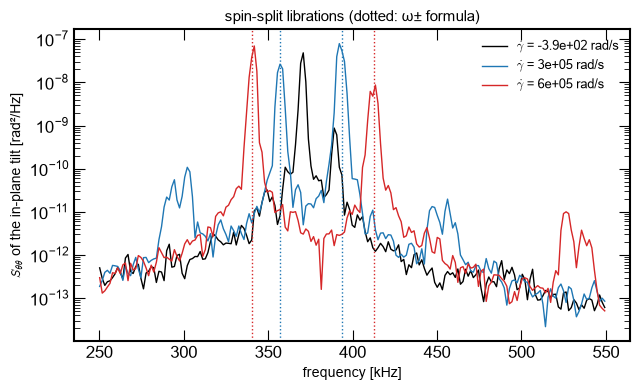

In [7]:
trap_nl = Trap(tweezer=tweezer(), particle=ellipsoid(), gas=Gas(P=1e-3*mbar, T=300.0), finite_size_torque=True)
I = np.diag(trap_nl.bead.inertia_tensor)
I1, I3 = 0.5 * (I[0] + I[1]), I[2]
ω_α, ω_β = trap_nl.Ωθ['γ'], trap_nl.Ωθ['α']  # paper's α (in plane) and β (out of plane)
fig, ax = plt.subplots(figsize=(6.5, 4))
for spin, colour in zip((0.0, 3e5, 6e5), ('k', 'C0', 'C3')):
    sim = RigidBodySimulation(trap=trap_nl, num_samples=200_000, Δt=1e-8, seed=2, ω0=(2e4, spin, 1e4))
    n = sim.lab_directions((0, 0, 1))
    spin_rate = np.mean(np.einsum('ni,ni->n', sim.angular_velocities_lab(), n))
    ω_c = I3 / I1 * spin_rate
    Q = np.sqrt(4 * ω_β**2 * ω_c**2 + (ω_c**2 + ω_α**2 - ω_β**2)**2)
    ω_minus, ω_plus = np.sqrt((ω_α**2 + ω_β**2 + ω_c**2 - Q) / 2), np.sqrt((ω_α**2 + ω_β**2 + ω_c**2 + Q) / 2)
    f_psd, S_θ = welch(-n[:, 0], fs=1 / sim.Δt, nperseg=2**16)
    band = (f_psd > 250e3) & (f_psd < 550e3)
    peaks, _ = find_peaks(S_θ[band], height=0.05 * S_θ[band].max())
    print(f'spin {spin_rate:9.3g} rad/s: ω±/2π formula {ω_minus / kHz:.1f}, {ω_plus / kHz:.1f} kHz; '
          f'simulated peaks {", ".join(f"{p / 1e3:.1f}" for p in f_psd[band][peaks])} kHz '
          f'(resolution {f_psd[1] / 1e3:.1f} kHz)')
    ax.semilogy(f_psd[band] / 1e3, S_θ[band], color=colour, lw=1, label=rf'$\dot\gamma$ = {spin_rate:.2g} rad/s')
    for ω in (ω_minus, ω_plus):
        if spin > 0:
            ax.axvline(ω / kHz, color=colour, ls=':', lw=1)
ax.set_xlabel('frequency [kHz]')
ax.set_ylabel(r'$S_{\theta\theta}$ of the in-plane tilt [rad²/Hz]')
ax.set_title('spin-split librations (dotted: ω± formula)', fontsize=11)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

The simulated peaks sit within 0.3–2.0 kHz (one or two 1.5 kHz bins) of the paper's ω±: the gyroscopic coupling
of the two librations through the spin is in the rigid-body equations of motion. At room temperature
the spin rate diffuses (its potential is 4–13 K deep for the two radii with the finite-size torque, 8–26 K without), so a spectrum averaged over many
spin states shows the broad Gaussian peaks of the paper's high-pressure data; at low pressure, once
the spin is confined, the peaks return to the linear frequencies.

## Summary

| Quantity | Paper | levisim | Verdict |
|---|---|---|---|
| spin libration (γ) | 17 kHz (Δr = 0.5 nm), 33 kHz (1.7 nm); 32 kHz observed | 17.7 / 32.3 kHz (point-dipole torques); 12.7 / 23.1 kHz with the finite-size torque (default) | point dipole agrees with the paper's analytic model; the finite-size torque lowers the spin frequency (open question) |
| in-plane and out-of-plane librations | 357 / 377 kHz | 369.9 / 379.7 kHz (nominal), 357.7 / 380.0 kHz (+1σ); dressed by the cavity 360 kHz | within 4 % (+1σ: 0.2 % / 0.8 %) |
| translations | 148 / 135 / 33 kHz | 166 / 154 / 48 kHz | 12–45 % high (paraxial tweezer at NA 0.77) |
| gas damping per mbar | 533–758 Hz | 632–763 Hz | 0–19 % |
| cavity-axis COM (y) | 212 ± 16 μK | 0.04 mK | colder (laser frequency noise not modelled) |
| beam-axis COM (z) | 6 ± 2 mK | 0.14 mK | colder (the paper's spin coupling and frequency noise not modelled) |
| in-plane libration (α) | 6.3 ± 1.4 mK | 16.5 mK | within a factor 3; sensitive to ψ and Φ |
| polarisation-axis COM (x), out-of-plane libration (β), spin (γ) | 126 μK, 4.4 mK, confined | not cooled | need the beam-polarised cavity mode and the cavity angle (not modelled / not given) |
| ω± with a spinning particle | formula | simulated peaks within 0.3–2.0 kHz of the formula | agree |
| nonlinear cavity traces | — | translations agree with the nonlinear model's linearisation about its displaced equilibrium (≈ 0.1 μm off focus) | consistency check |

Not reproduced: the second, beam-polarised cavity mode (it carries the cooling of β and γ), the
nonlinear cavity dynamics of the librations (`model='nonlinear'` is translational), laser frequency
noise, and the pressure-dependent transition of the spin from running to confined.

In [8]:
print(f'computation time {time.time() - t_start:.1f} s')

computation time 24.8 s
